<h1><center>Diabetes</center></h1>

## Abstract

People with type 1 diabetes are unable to produce the hormone insulin. 

Keywords: python, seaborn, numpy, plotly, pandas, matplotlib, scikit-learning, multiple linear regression, polynomial regression, decision tree, random forest, regression, logistic regression, machine learning




## Objective

This project seeks explore a diabetes dataset in order to 



This project seeks to better understand the various factors that affect life expectancy and their relationship with each other and life expectancy itself.  The project will also use various machine learning techniques to predict various life expectancies by country and other indicators and provide the metrics needed to evaluate the predictions.

Conduct EDA on the diabetes dataset and build an ensemble classifier to improve the AUC score.

## The Data
This dataset is a part of a large dataset held at the National Institute of Diabetes and Digestive and Kidney Diseases and was obtained through https://data.world/

The target variable is specified as "outcome", where 1 indicates a positive result of the diabetes test and 0 indicates a negative result.

A machine learning model is requested to be developed that can predict whether individuals have diabetes or not when their features are given. Before developing the model, performing the necessary data analysis and feature engineering steps are expected.

### There are 9 variables in the dataset:

<li>Pregnancies: Number of pregnancies.</li>
<li>Glucose: 2-hour plasma glucose concentration during an oral glucose tolerance test.</li>
<li>Blood Pressure: Blood Pressure (Diastolic) (mm Hg).</li>
<li>SkinThickness : Thickness of skin</li>
<li>Insulin: 2-Hour Serum Insulin (mu U/ml)</li>
<li>DiabetesPedigreeFunction: Function (2-hour plasma glucose concentration during an oral glucose tolerance test).</li>
<li>BMI: Body Mass Index (weight in kg/(height in meters)^2)</li>
<li>Age: Persons age(in years)</li>
<li>Outcome: Having diabetes status (1: diabetes, 0: no diabetes)</li>

## Importing Python libraries

In [ ]:
# Import libraries
import os
import csv

# Import packages for EDA and Data Visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from matplotlib import pyplot

# Images
import dataframe_image as dfi
from IPython.display import Image

#Statistical Functions
from IPython.display import display, HTML
from scipy.stats import stats
from scipy.stats.mstats import winsorize

SEED = 42  # random seed for modeling

# Import Classes for Model Traning and Feature Exploration / Engineering 
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split, cross_val_score
from scipy.stats import mstats

# Linear Models & Metrics
import numpy as np
from sklearn import metrics
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, accuracy_score, \
    classification_report, roc_auc_score, roc_curve
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from ydata_profiling import ProfileReport

# Plotting
import plotly.graph_objects as go

# Decision Tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier 
from sklearn.tree import export_graphviz
from io import StringIO
import pydotplus
import six
import sys
sys.modules['sklearn.externals.six'] = six
from IPython.display import Image 




## Loading the Dataset

In [ ]:
# GLOBAL VARIABLES
# Load data into pandas data frame
pd.set_option('display.width', 480)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option("display.max_columns", 20)
df = pd.read_csv('diabetes.csv')
feature_cols = ['Pregnancies', 'Glucose','BloodPressure','SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
num_cols = [col for col in df.columns if df[col].dtypes != "O"]

wins_df = pd.DataFrame()  # Winsorized dataframe holder

wins_dict = {}  # Winsorized feature dictionary
#feature_vars = list(df.columns)[:8]  # List of numerical features

# Check for directory called charts, create it if it doesn't exist
directory = "charts"

if not os.path.exists(directory):
    os.makedirs(directory)
    print(f"Directory '{directory}' created.")
else:
    print(f"Directory '{directory}' already exists.")

Directory 'charts' already exists.


In [ ]:
df.shape

(768, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [ ]:
df.head(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1


In [ ]:
df.tail(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.900,0.171,63,0
764,2,122,70,27,0,36.800,0.340,27,0
765,5,121,72,23,112,26.200,0.245,30,0
766,1,126,60,0,0,30.100,0.349,47,1
767,1,93,70,31,0,30.400,0.315,23,0


In [ ]:
# Write charts to image files
def view_df_to_image(text_body, file_name):
    df_styled = text_body.style.background_gradient()  # Style the text
    dfi.export(df_styled, 'charts/' + file_name + '.png')  # Create image of text
    
# Write dataframe info to images
dfi.export(pd.DataFrame(df.dtypes).style.background_gradient(), 'charts/Orig_Column_Headings.png')

text_body = df.head(5)
view_df_to_image(text_body, 'Head(5)')
df_styled = text_body.style.background_gradient()  # Style the text
dfi.export(df_styled, 'charts/' + 'Head(5)' + '.png')  # Create image of text

text_body = df.tail(5)
view_df_to_image(text_body, 'Tail(5)')
df_styled = text_body.style.background_gradient()  # Style the text
dfi.export(df_styled, 'charts/' + 'Tail(5)' + '.png')  # Create image of text

## Exploratory Data Analysis

In exploratory data analysis, the type of the variables (e.g. integer or decimal) is first printed, the sum of the missing values (either null or na) is calculated, and it is found that no such value exists.
In addition, some statistical measures are calculated to understand their variation. Some of these statistical measures are the mean of each column, the median, the standard deviation, the percentages, etc.

In [ ]:
# Check for duplicate values
df.duplicated().any()

False

No duplicates found, we have a clean dataframe.

We can view the outcome distrubution and counts with bar and pie charts.  0 = no diabetes while 1 equals diabetes present. 

### Binary Classification Imbalance
Next, let's take a look at the proportion of classes.

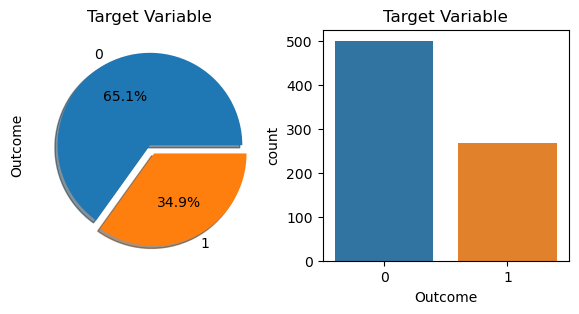

In [36]:
f,ax=plt.subplots(1,2,figsize=(7,3))
df['Outcome'].value_counts().plot.pie(explode=[0,0.1],autopct='%1.1f%%',ax=ax[0],shadow=True)
ax[0].set_title('Target Variable')
ax[0].set_ylabel('Outcome')
sns.countplot(x='Outcome',data=df)
ax[1].set_title('Target Variable')
plt.show()



### Univariant Analysis (Five - Point Summary)

Now we will examine the distrubtion of all the attributes in the dataset by Outcome - the dark blue data points.

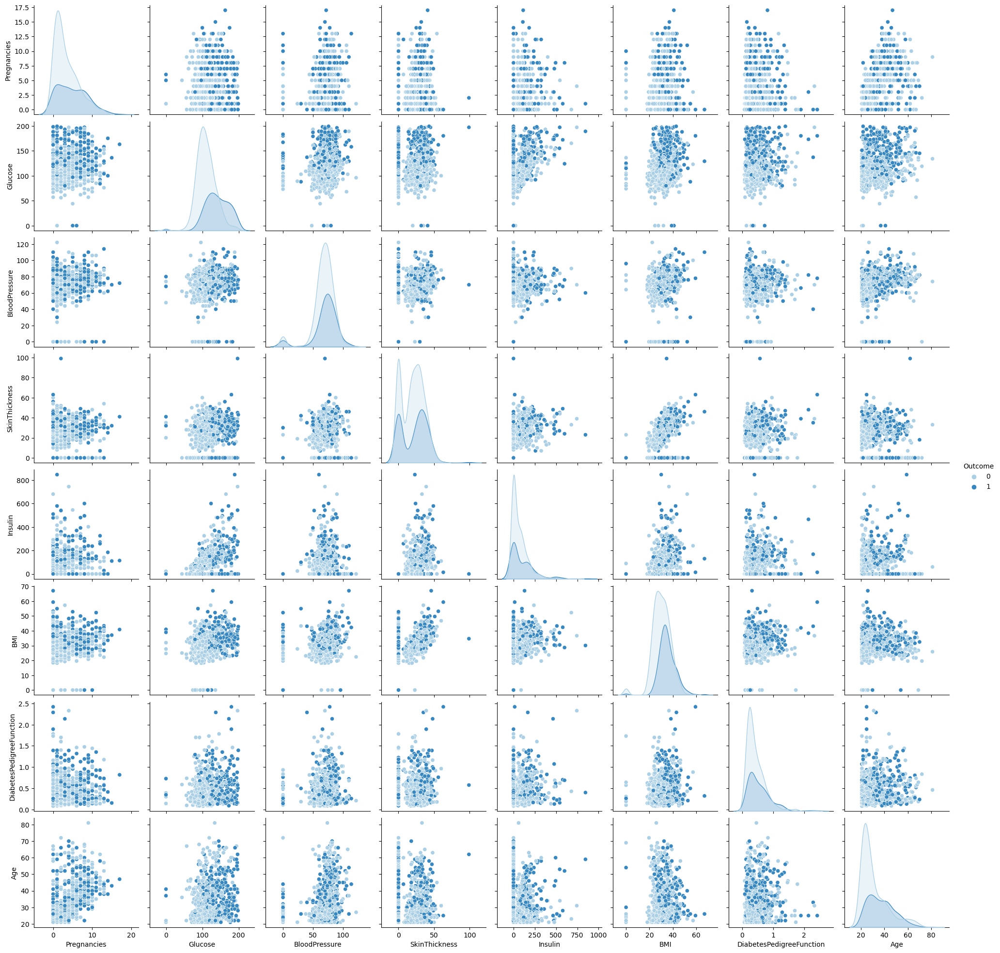

In [ ]:
sns.pairplot(df, hue='Outcome', palette="Blues")
plt.show()

Here are a few observations:

<li>There are less younger women that have diabetes, compared to women in their 30s-50s.</li>
<li>Women that have diabetes have higher BMI.</li>
<li>Diabetes pedigree function is lower for women that have diabetes; Same thing with insulin & glucose.</li>
<li>Pregnacies are also lower among women that have diabetes.</li>
<li>There are outliers present in almost all of the attributes.</li>

In [ ]:
# Describe view stats on dataframe
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.000,3.845,3.370,0.000,1.000,3.000,6.000,17.000
Glucose,768.000,120.895,31.973,0.000,99.000,117.000,140.250,199.000
BloodPressure,768.000,69.105,19.356,0.000,62.000,72.000,80.000,122.000
SkinThickness,768.000,20.536,15.952,0.000,0.000,23.000,32.000,99.000
Insulin,768.000,79.799,115.244,0.000,0.000,30.500,127.250,846.000
BMI,768.000,31.993,7.884,0.000,27.300,32.000,36.600,67.100
DiabetesPedigreeFunction,768.000,0.472,0.331,0.078,0.244,0.372,0.626,2.420
Age,768.000,33.241,11.760,21.000,24.000,29.000,41.000,81.000
Outcome,768.000,0.349,0.477,0.000,0.000,0.000,1.000,1.000


Using describe() above we can see that there are no missing values.  

## Null Summary
Missing values can exist when we have nulls, but there can also be erroneous missing values when the values appear to be inexplicit. Inexplicit nulls may require a more discretion when deciding how to deal with them as they may still represent actual data. "isnull" reveals that we have no null values.

In [ ]:
# NULLS
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
#def null_summary():
na_values = df.isna().sum().reset_index()  # Find NA values
na_values.columns = ["Features", "Missing_Values"]
na_values["Missing_Percent"] = round(na_values.Missing_Values / len(df) * 100, 2)
print("Summarize NULLS: \n", na_values[na_values.Missing_Values > 0])

df_nulls = na_values[na_values.Missing_Values > 0]
dfi.export(pd.DataFrame(df_nulls).style.background_gradient(), 'charts/Summarize_Nulls.png')  # Print to image
df.info()  

Summarize NULLS: 
 Empty DataFrame
Columns: [Features, Missing_Values, Missing_Percent]
Index: []
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


No NULL values so no need to deal with implicit or explicit NULL values from the original dataset.

## Missing Value Imputation - Iterative Imputer

#### Before Imputation

With imputation we are looking for zero values in 4 specific columns - bloodPressure, BMI, glucose, and skinthickness as none of them should contains zero values. Columns like insulin and pregnancies may legitimately contain zero values. 

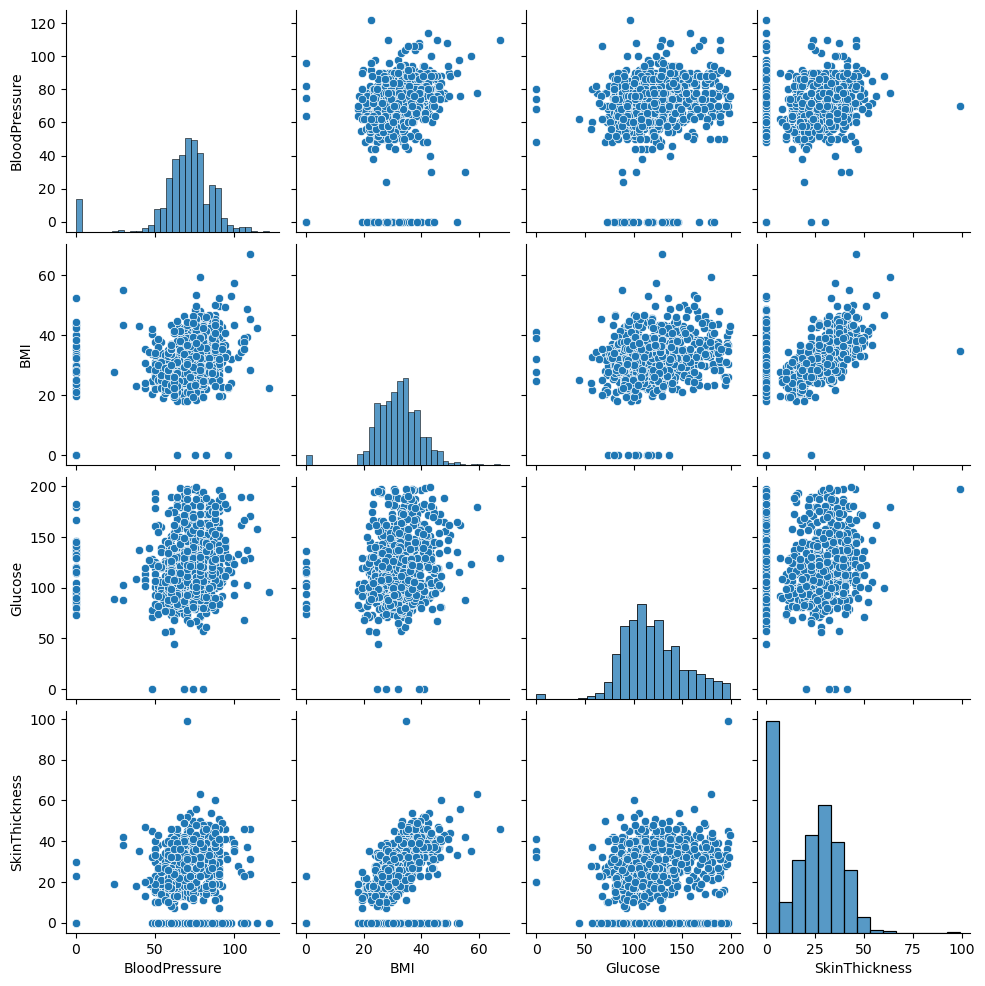

In [ ]:
# Define columns with missing values
missing_colsDF = df[['BloodPressure','BMI', 'Glucose', 'SkinThickness']]
    
# Show the pairplot
sns.pairplot(missing_colsDF)
plt.show()

Looking at the charts above we can see all the zero values 

#### To address the zero values we'll replace them with NaN values

In [ ]:
# Replace zeroes with np.nan
missing_colsDF = missing_colsDF.replace(0, np.nan)
print(missing_colsDF.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   BloodPressure  733 non-null    float64
 1   BMI            757 non-null    float64
 2   Glucose        763 non-null    float64
 3   SkinThickness  541 non-null    float64
dtypes: float64(4)
memory usage: 24.1 KB
None


#### After Imputation

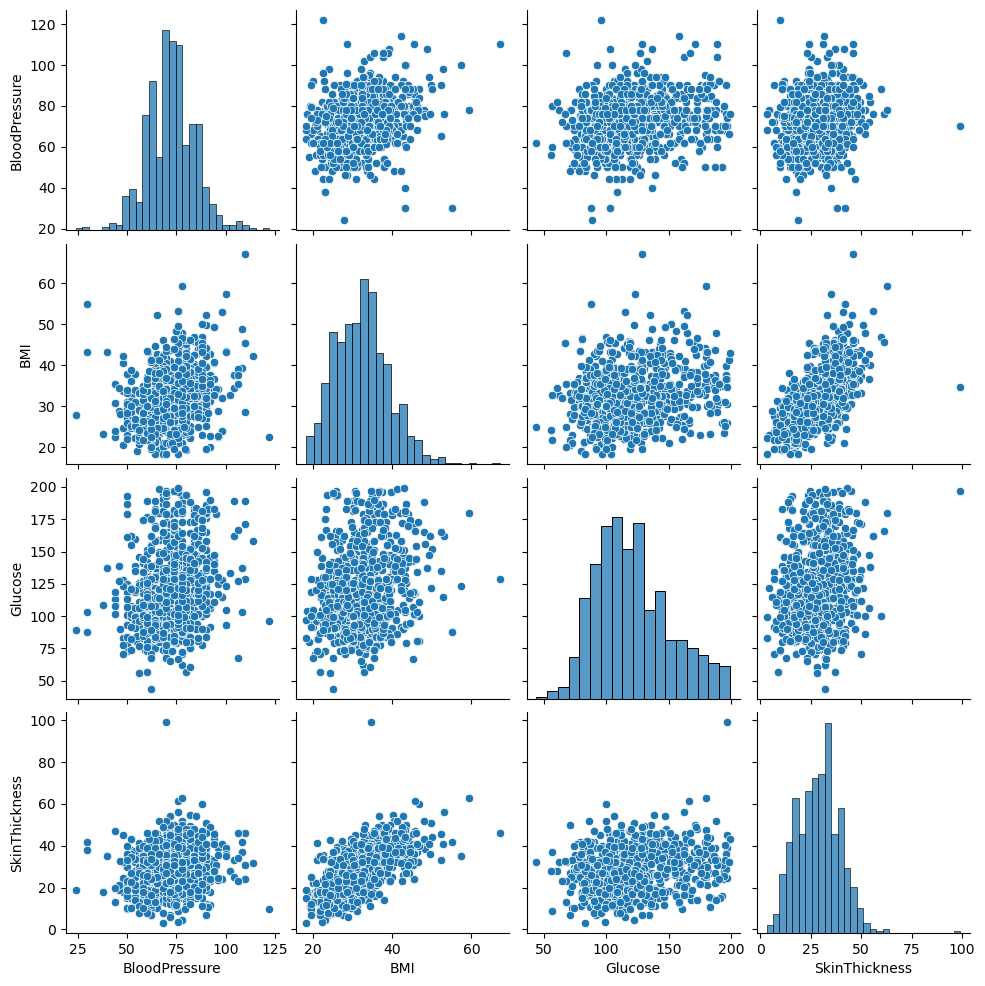

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   BloodPressure  768 non-null    float64
 1   BMI            768 non-null    float64
 2   Glucose        768 non-null    float64
 3   SkinThickness  768 non-null    float64
dtypes: float64(4)
memory usage: 24.1 KB
None



In [ ]:
# Iteratively impute
imp_iter = IterativeImputer(max_iter=5, sample_posterior=True, random_state=SEED)
diabetes_imp_iter = imp_iter.fit_transform(missing_colsDF)

# Convert returned array to DataFrame
diabetes_imp_iterDF = pd.DataFrame(diabetes_imp_iter, columns=missing_colsDF.columns)

# Show the pairplot
sns.pairplot(diabetes_imp_iterDF)
plt.show()

# Check the DataFrame's info
print(diabetes_imp_iterDF.info())
print()

Comparing the before and after imputation charts we can see the disappearance of the zero values givng us more reliable data.

## Outliers

Outliers are the extreme value within the dataset and can have a big impact on statistical analysis as the can impact calculations like mean and standard deviation. 

First we'll view a quick numerical breakdown followed by histograms and boxpolots.

In [ ]:
#outlier_summary(),  count outliers and plot
with open('charts/Outlier_Summary.txt', mode='w', newline='') as outlier_file:
    outlier_writer = csv.writer(outlier_file, delimiter=',', quotechar='"', quoting=csv.QUOTE_MINIMAL)
    for col in feature_cols:
        q75, q25 = np.percentile(df[col], [75, 25])
        iqr = q75 - q25
        min_val = q25 - (iqr * 1.5)
        max_val = q75 + (iqr * 1.5)
        count = len(np.where((df[col] > max_val) | (df[col] < min_val))[0])
        percent = round(count / len(df[col]) * 100, 2)

        total_chars = 45
        len_first_chars = 7
        len_col = len(col)
        chars_needed = total_chars - len_col - len_first_chars

        print(len_first_chars * '-' + col + ' Outliers' + chars_needed * '-')
        print('Count: {}'.format(count))
        print('Percentage of Data: {}%'.format(percent))

        outlier_writer.writerow([len_first_chars * '-' + col + ' Outliers' + chars_needed * '-'])
        outlier_writer.writerow(['Count: {}'.format(count)])
        outlier_writer.writerow(['Percentage of Data: {}%'.format(percent)])
        outlier_writer.writerow(' ')

-------Pregnancies Outliers---------------------------
Count: 4
Percentage of Data: 0.52%
-------Glucose Outliers-------------------------------
Count: 5
Percentage of Data: 0.65%
-------BloodPressure Outliers-------------------------
Count: 45
Percentage of Data: 5.86%
-------SkinThickness Outliers-------------------------
Count: 1
Percentage of Data: 0.13%
-------Insulin Outliers-------------------------------
Count: 34
Percentage of Data: 4.43%
-------BMI Outliers-----------------------------------
Count: 19
Percentage of Data: 2.47%
-------DiabetesPedigreeFunction Outliers--------------
Count: 29
Percentage of Data: 3.78%
-------Age Outliers-----------------------------------
Count: 9
Percentage of Data: 1.17%


#### Histogram for Outliers

A histogram is the best way to check univariate data — data containing a single variable — for outliers.

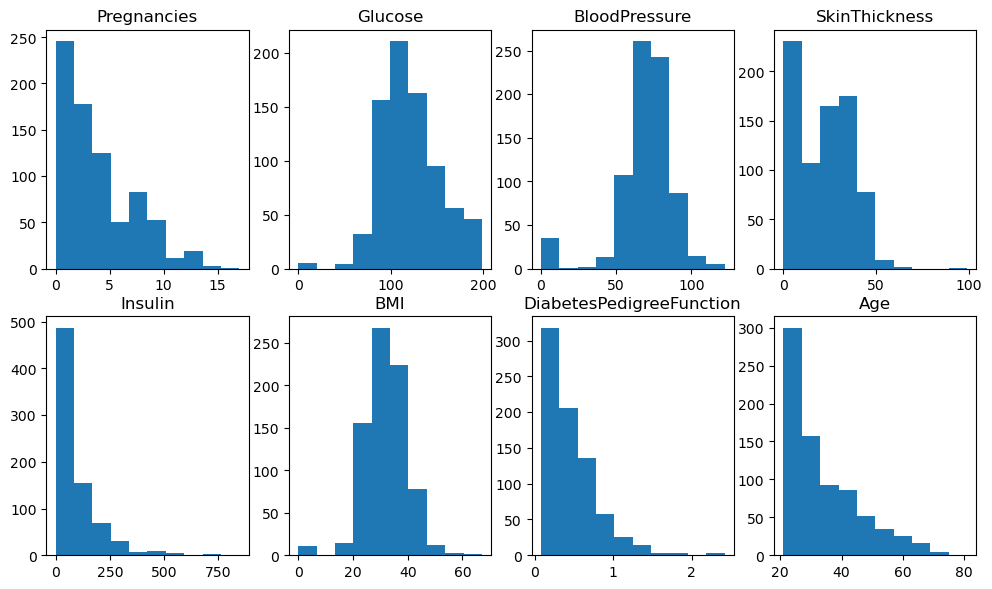

In [ ]:
# visualize dist():
plt.figure(figsize=(12, 18))
for i, col in enumerate(feature_cols, 1):
    plt.subplot(5, 4, i)
    plt.hist(df[col])
    plt.title(col)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
plt.savefig('charts/Visualize_Winsorized.png', dpi=None, facecolor='w', edgecolor='g', orientation='portrait',
            format=None, transparent=False, bbox_inches=None, pad_inches=0.10, metadata=None)
plt.show()

#### Boxplots for Outliers

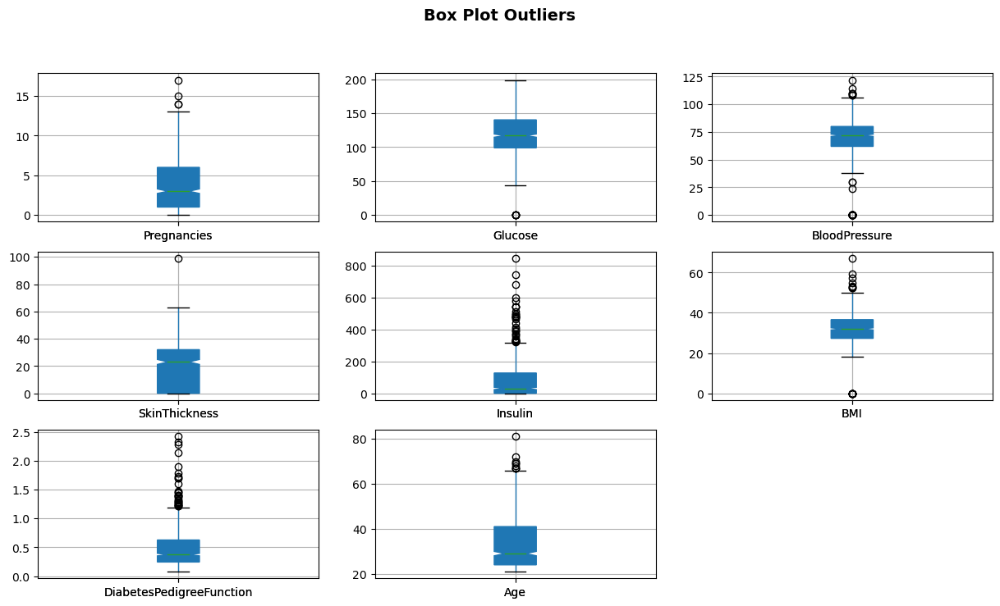

In [ ]:
# Box plots for the potential outliers
%matplotlib inline
#outlier_features = ['Adult_Mortality', 'Infant_Deaths', 'BMI', 'Under-Five_Deaths', 'GDP', 'Population']
plt.figure(figsize=(15, 8))

for i, col in enumerate(feature_cols, start=1):
    plt.subplot(3, 3, i)
    plt.xticks([1, 2, 3, 4, 5, 6, 7, 8], feature_cols)
    df.boxplot(col, notch=True, patch_artist=True)

pyplot.suptitle('Box Plot Outliers', fontsize=14, verticalalignment='top', horizontalalignment='center',
                fontweight='bold')
plt.savefig('charts/BoxPlot_Outliers.png', dpi=None, facecolor='w', edgecolor='g', orientation='landscape',
            format=None, transparent=False, bbox_inches=None, pad_inches=0.10, metadata=None)
plt.show()

REWRITE

As mentioned earlier, potassium (K) has a large variance between the 75% percentile and the max figure. A higher standard deviation tells us that the data has a high variation (greater number of outliers) indicating less reliable, and the boxplot shows the severe variance as well. The boxplots also shows a large variance for phosphorous (P) which maybe was quite as evident when using describe().

The boxplots make it easier to see that the only columns that have a smaller variance are nitrogen (N) and humidity, both around the 50% core region. Nitrogen (N) shows a significant right skew while humidty shows a skew left.

The wiskers for temperature and ph show short tails while rainfall, nitrogen (N) and phosphorous (P) show heavy tails, while potasium (K) and humidity show moderate tails. Tails represent the extremities of the population.

### Windsorization
Let's work with the outliers.

Because there are a number of features with outlier issues and each one has its own unique issues, the method I will use to address outliners is to Winsorize the data.  This method will help to minimize that influence that outliers have on each variable.  Winsorizing the data will enable me to set upper and lower limits on each feature.  This limits the outlier’s severity and influence on the data.  

The parameters for winsorizing will be stored in a dictionary for easy access later in the project.

In [ ]:
def winsorizeDF(df: pd.DataFrame) -> pd.DataFrame:
    """
    Replace outliers with 5th and 95th percentile values.
    """
    return df.apply(lambda x: mstats.winsorize(x, limits=[.05, .05]))

# apply winsorize and show summary stats
diabetes_winDF = winsorizeDF(df.drop('Outcome', axis=1))
diabetesDF = diabetes_winDF.join(df['Outcome'])
display(diabetesDF.describe())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000
mean,3.742,121.344,70.404,20.240,72.462,32.164,0.457,32.952,0.349
std,3.124,28.989,13.013,15.316,90.569,6.362,0.277,11.007,0.477
min,0.000,79.000,38.000,0.000,0.000,21.800,0.140,21.000,0.000
25%,1.000,99.000,62.000,0.000,0.000,27.300,0.244,24.000,0.000
50%,3.000,117.000,72.000,23.000,30.500,32.000,0.372,29.000,0.000
75%,6.000,140.250,80.000,32.000,127.250,36.600,0.626,41.000,1.000
max,10.000,181.000,90.000,44.000,293.000,44.500,1.136,58.000,1.000


Outliers have been replaced!

## Train, Test, and Evaluate Model 
So here we are, ready to model and predict!  In this section we'll walk through logistical regression, linear regression, multiple regression, polynomial regression, decision tree, random forest.

### Create Training Data

Let's split the dataset by using the function train_test_split(). You need to pass three parameters features; target, and test_set size.

In [ ]:
# Feature variables
x=df.drop(['Outcome'], axis=1)
x

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.600,0.627,50
1,1,85,66,29,0,26.600,0.351,31
2,8,183,64,0,0,23.300,0.672,32
3,1,89,66,23,94,28.100,0.167,21
4,0,137,40,35,168,43.100,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.900,0.171,63
764,2,122,70,27,0,36.800,0.340,27
765,5,121,72,23,112,26.200,0.245,30
766,1,126,60,0,0,30.100,0.349,47


In [ ]:
# Ttarget variable
y=df.Outcome
y

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

In [ ]:
# Split dataset into training set and test set
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=1) # 70% training and 30% test

In [ ]:
# Create Decision Tree classifer object
model = DecisionTreeClassifier()

# Train Decision Tree Classifer
model = model.fit(x_train,y_train)

# Predict the response for test dataset
y_pred = model.predict(x_test) 

### Evaluating the Model
Let's estimate how accurately the classifier or model can predict the type of cultivars.

Accuracy can be computed by comparing actual test set values and predicted values

First let's evaluate using Accuracy Score

In [ ]:
print("Accuracy:",metrics.accuracy_score(y_test, y_pred)*100)

Accuracy: 68.83116883116884


We get a classification rate of between 67%-72%, which is considered as good accuracy. We can improve this accuracy by tuning the parameters in the decision tree algorithm.

In Scikit-learn, optimization of decision tree classifier performed by only pre-pruning. Maximum depth of the tree can be used as a control variable for pre-pruning. In the following the example, you can plot a decision tree on the same data with max_depth=3. Other than pre-pruning parameters, we can also try other attribute selection measure such as entropy.

Next let's evaluate using a Confusion Matrix

In [ ]:
confusion_matrix(y_test,y_pred)

array([[117,  29],
       [ 43,  42]], dtype=int64)

Model Accuracy, how often is the classifier correct?

In [ ]:
print("Accuracy:",((82+27)/154))

Accuracy: 0.7077922077922078


Evaluation using Classification Report

In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.73      0.80      0.76       146
           1       0.59      0.49      0.54        85

    accuracy                           0.69       231
   macro avg       0.66      0.65      0.65       231
weighted avg       0.68      0.69      0.68       231



Evaluation using Classification report

In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.73      0.80      0.76       146
           1       0.59      0.49      0.54        85

    accuracy                           0.69       231
   macro avg       0.66      0.65      0.65       231
weighted avg       0.68      0.69      0.68       231



In [ ]:
# Checking prediction value
model.predict([[6,148,72,35,0,33.6,0.627,50]])

C:\Users\sschi\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0], dtype=int64)

In [ ]:
features=x.columns
features

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age'], dtype='object')

## Decision Tree
Let's create a decision tree model using Scikit-learn

In [ ]:
features=x.columns
features

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age'], dtype='object')

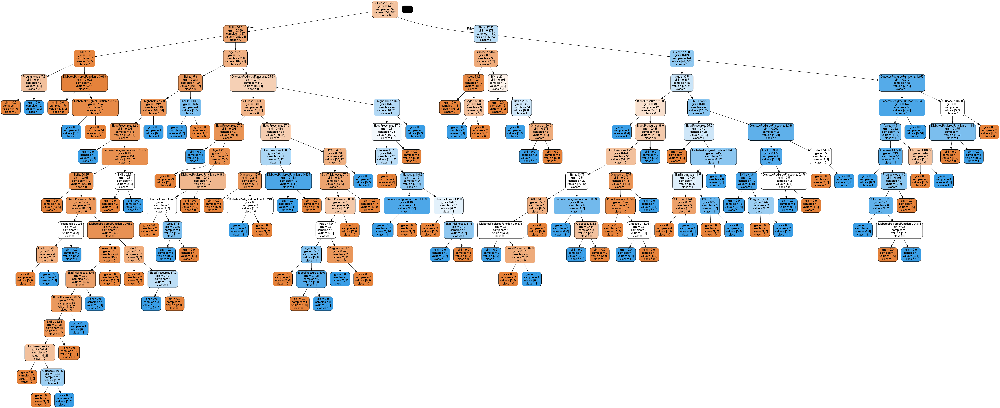

In [ ]:
dot_data = StringIO()
export_graphviz(model, out_file=dot_data,filled=True, rounded=True,special_characters=True,feature_names = features,class_names=['0','1'])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('diabetes_set.png')
Image(graph.create_png())

Next we can use ProfileReport to do a quick EDA as an extended analysis of the dataframe.

In [ ]:
profile = ProfileReport(df, title="Diabetes Classification")
profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]